# Figures for the report

Every figure is built from CSVs already produced; nothing is recomputed here.
Run the setup cell, then any figure cell on its own.

Each is sized for IEEE double column: 3.4 in for a single-column figure,
7.0 in for one spanning both. Text is 8 pt to match the body.

| | figure | source |
|---|---|---|
| 1 | reproduction, ours vs published, 142 datasets | `theirs142/results.csv` |
| 2 | critical difference, QUANT vs interval baselines | `domain_per_dataset.csv` |
| 3 | accuracy vs classifier time, three groups | `reduction_v2_results.csv` |
| 4 | accuracy by budget and strategy | `reduction_v2_results.csv` |
| 5 | Fig. 8 reproduced, with confidence intervals | `fig8_results.csv` |
| 6 | depth shares kept by each strategy | computed from provenance |
| 7 | weighting, difference from baseline by depth | `weighting_v3_results.csv` |
| 8 | accuracy, macro-F1 and balanced accuracy | `reduction_f1_results.csv` |

## Setup

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from pathlib import Path

ROOT = Path(os.environ.get("QUANT_ROOT", Path.cwd().parent))
FIGDIR = str(Path.cwd().parent / "figures")
os.makedirs(FIGDIR, exist_ok=True)
sys.path.append(str(ROOT / "src"))

# IEEE double column
ONE_COL, TWO_COL = 3.4, 7.0

plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 9,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "grid.linewidth": 0.4,
    "axes.axisbelow": True,
    "figure.dpi": 130,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

GROUPS = ["small", "random", "large"]


def save(fig, name):
    """PDF for LaTeX, PNG to look at."""
    for ext in ("pdf", "png"):
        fig.savefig(f"{FIGDIR}/{name}.{ext}")
    print(f"wrote figures/{name}.pdf and .png")


def camel(n):
    """Our folder names -> the published CSV's names."""
    return (n.replace("_eq", "Eq")
             .replace("_disc", "Discrete")
             .replace("_nmv", "Nmv"))


def tidy_log_x(ax):
    """Log axes default to cluttered minor labels; show only decades."""
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda v, _: f"{v:g}"))


print("ready")

ready


## 1 — Reproduction

Their code, run here on all 142 datasets with the official resample indices,
against the accuracies shipped in the repo. One point per dataset.

The four datasets whose test sets the bake-off erratum corrected are marked
separately: they are the four largest differences in the archive and all fall
on the same side.

142 datasets matched of 142
wrote figures/fig_reproduction.pdf and .png


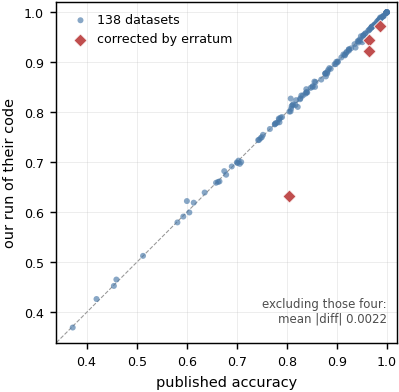

In [2]:
mine = pd.read_csv(f"{ROOT}/results/theirs142_results.csv")
pub = pd.read_csv(f"{ROOT}/Quant/quant-main/quant-main/results/"
                  "accuracy_resamples_ucr142.csv")
pub = pub.set_index(pub.columns[0])

m = mine.groupby("dataset")["accuracy"].mean()
rows = [(camel(n), v, float(pub.loc[camel(n)].astype(float).mean()))
        for n, v in m.items() if camel(n) in pub.index]
d = pd.DataFrame(rows, columns=["dataset", "ours", "published"])
print(f"{len(d)} datasets matched of {len(m)}")

ERRATUM = ["Covid3MonthDiscrete", "FloodModeling1Discrete",
           "FloodModeling2Discrete", "FloodModeling3Discrete"]
is_err = d["dataset"].isin(ERRATUM)

fig, ax = plt.subplots(figsize=(ONE_COL, ONE_COL))
lo = min(d.ours.min(), d.published.min()) - 0.03
ax.plot([lo, 1], [lo, 1], "--", color="0.6", lw=0.6, zorder=1)
ax.scatter(d.loc[~is_err, "published"], d.loc[~is_err, "ours"],
           s=11, alpha=0.65, edgecolor="none", color="#4878a8",
           label=f"{(~is_err).sum()} datasets", zorder=2)
ax.scatter(d.loc[is_err, "published"], d.loc[is_err, "ours"],
           s=26, color="#c04e4e", marker="D", edgecolor="white",
           linewidth=0.4, label="corrected by erratum", zorder=3)

ax.set_xlabel("published accuracy")
ax.set_ylabel("our run of their code")
ax.set_xlim(lo, 1.02)
ax.set_ylim(lo, 1.02)
ax.set_aspect("equal")
ax.legend(loc="upper left", frameon=False, handletextpad=0.3)

clean = d[~is_err]
ax.text(0.97, 0.05,
        f"excluding those four:\nmean |diff| "
        f"{np.abs(clean.ours - clean.published).mean():.4f}",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=6.5,
        color="0.3")

save(fig, "fig_reproduction")
plt.show()

## 2 — Critical difference diagram

QUANT against the interval methods it is compared with, on the 112-dataset
subset, using the published results for the baselines.

A Friedman test comes first: a post-hoc pairwise comparison is only justified
if the omnibus test rejects. The paper reports pairwise Wilcoxon tests without
one.

`domain_per_dataset.csv` must hold one row per dataset with a column per
method. Adjust `methods` if the columns are named differently.

In [3]:
from scipy.stats import friedmanchisquare

path = f"{ROOT}/results/results_with_baselines.csv"
df = pd.read_csv(path, index_col=0)
print("columns:", list(df.columns))

# STSF is in the paper's Fig. 1 but absent from aeon's copy of the bake-off
# results, so it is omitted. QUANT here is the published column, so every
# method is compared on published numbers.
methods = [c for c in ["QUANT", "DrCIF", "RSTSF", "CIF", "TSF"]
           if c in df.columns]
scores = df[methods].dropna()
print(f"\n{len(scores)} datasets, {len(methods)} methods: {methods}")

stat, p = friedmanchisquare(*[scores[m] for m in methods])
print(f"\nFriedman chi2 = {stat:.2f}, p = {p:.3e}")
print("-> a post-hoc comparison is justified" if p < 0.05
      else "-> no evidence of any difference; post-hoc tests not justified")

print("\nmean rank (1 = best):")
print(scores.rank(axis=1, ascending=False).mean().sort_values().round(3)
      .to_string())

columns: ['QUANT', 'QUANT_ours', 'DrCIF', 'RSTSF', 'CIF', 'TSF', 'Type', 'TrainSize', 'TestSize', 'Length', 'NumberClasses']

112 datasets, 5 methods: ['QUANT', 'DrCIF', 'RSTSF', 'CIF', 'TSF']

Friedman chi2 = 212.36, p = 8.246e-45
-> a post-hoc comparison is justified

mean rank (1 = best):
QUANT    2.098
DrCIF    2.295
RSTSF    2.580
CIF      3.277
TSF      4.750


In [4]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# zero_method="pratt" reproduces the paper's p-values exactly; the scipy
# default ("wilcox") discards zero differences and gives slightly larger ones.
baselines = [m for m in methods if m != "QUANT"]
raw = [wilcoxon(scores["QUANT"], scores[m], zero_method="pratt").pvalue
       for m in baselines]
rej, adj, _, _ = multipletests(raw, alpha=0.05, method="holm")

print(f"{'baseline':<10}{'mean diff':>11}{'raw p':>9}{'Holm p':>9}  verdict")
for m, p, a, r in zip(baselines, raw, adj, rej):
    d = (scores["QUANT"] - scores[m]).mean()
    print(f"{m:<10}{d:>+11.4f}{p:>9.4f}{a:>9.4f}  "
          f"{'significant' if r else 'not significant'}")

baseline    mean diff    raw p   Holm p  verdict
DrCIF         +0.0035   0.1442   0.1442  not significant
RSTSF         +0.0031   0.0277   0.0553  not significant
CIF           +0.0193   0.0000   0.0000  significant
TSF           +0.0650   0.0000   0.0000  significant


wrote figures/fig_cd.pdf and .png


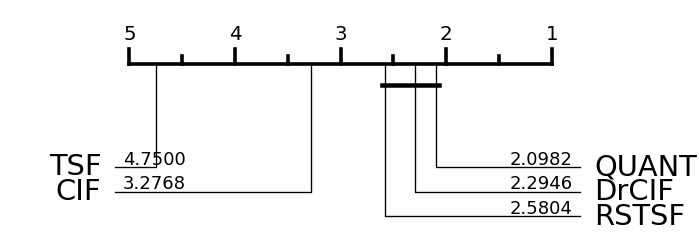

In [5]:
from aeon.visualisation import plot_critical_difference

# Both available post-hoc tests - Nemenyi (the classic Demsar version) and
# Wilcoxon-Holm (aeon's default, more powerful) - give the same clique
# structure on these results, so only one diagram is kept. aeon defaults to
# alpha=0.1; 0.05 matches the Friedman test above.
fig, _ = plot_critical_difference(scores.to_numpy(), methods,
                                  lower_better=False, test="wilcoxon",
                                  alpha=0.05)
# wider than one column, then scaled down by LaTeX: at 3.4in the method
# labels collide with the rank axis
fig.set_size_inches(5.2, 1.9)
save(fig, "fig_cd")
plt.show()

wrote figures/fig_mcm_quant_vs_baselines.pdf and .png


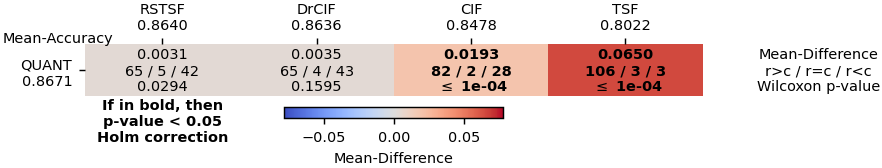

In [6]:
from aeon.visualisation import create_multi_comparison_matrix

# The format of the paper's own Fig. 1: one row for QUANT against every
# baseline, each cell giving the mean difference, the win/draw/loss record
# and the p-value. Restricting to one row reproduces that layout.
fig = create_multi_comparison_matrix(
    scores,
    used_statistic="Accuracy",
    higher_stat_better=True,
    row_comparates=["QUANT"],
    excluded_col_comparates=["QUANT"],
    pvalue_test="wilcoxon",
    pvalue_test_params={"alternative": "two-sided", "zero_method": "wilcox"},
    pvalue_correction="Holm",
    pvalue_threshold=0.05,
    formats=None,
    fig_size=(7.0, 1.5),
    font_size=8,
)
save(fig, "fig_mcm_quant_vs_baselines")
plt.show()

## 3 — Accuracy against classifier time

The trade-off the improvement is about. One panel per dataset group, log time
axis, single-core.

The transform share in each title is what bounds the end-to-end gain:
selection cannot reduce it.

wrote figures/fig_tradeoff.pdf and .png


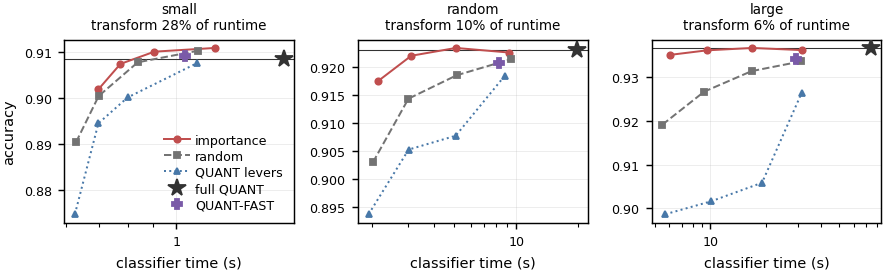

In [7]:
df = pd.read_csv(f"{ROOT}/results/reduction_v2_results.csv").drop_duplicates(
    ["group", "dataset", "fold", "strategy", "budget"])
df["classifier_s"] = df["select_s"].fillna(0) + df["fit_s"]
df["total_s"] = df["transform_s"] + df["classifier_s"]

per = (df.groupby(["group", "strategy", "budget"])
       [["accuracy", "classifier_s", "transform_s", "total_s"]]
       .mean().reset_index())

fig, axes = plt.subplots(1, 3, figsize=(TWO_COL, 2.3))
for ax, group in zip(axes, GROUPS):
    g = per[per["group"] == group]
    if not len(g):
        ax.set_visible(False)
        continue
    full = g[g.strategy == "full"].iloc[0]
    fast = g[g.strategy == "fast"].iloc[0]
    share = full["transform_s"] / full["total_s"]

    for strat, label, colour, style, ms in [
            ("importance_sqrt", "importance", "#c04e4e", "o-", 3.5),
            ("random", "random", "0.45", "s--", 3),
            ("both", "QUANT levers", "#4878a8", "^:", 3)]:
        s = g[(g.strategy == strat) & (g.budget > 0)].sort_values("budget")
        if len(s):
            ax.plot(s.classifier_s, s.accuracy, style, ms=ms, lw=1.1,
                    color=colour, label=label, zorder=3)

    ax.axhline(full.accuracy, color="0.2", lw=0.6, zorder=1)
    ax.plot(full.classifier_s, full.accuracy, "*", ms=10, color="0.2",
            label="full QUANT", zorder=5)
    ax.plot(fast.classifier_s, fast.accuracy, "P", ms=5, color="#7a5aa8",
            label="QUANT-FAST", zorder=5)

    ax.set_xscale("log")
    tidy_log_x(ax)
    ax.set_title(f"{group}\ntransform {share:.0%} of runtime", fontsize=7.5)
    ax.set_xlabel("classifier time (s)")
    if group == GROUPS[0]:
        ax.set_ylabel("accuracy")
        ax.legend(loc="lower right", frameon=False, handletextpad=0.4,
                  labelspacing=0.25)

save(fig, "fig_tradeoff")
plt.show()

## 4 — Accuracy by budget

Change from the full model at each feature budget. Shows the 6.25% floor and
the depth lever collapsing.

Lever rows that cover fewer datasets than the full model are dropped: their
means are over a different subset and are not comparable.

wrote figures/fig_budget.pdf and .png


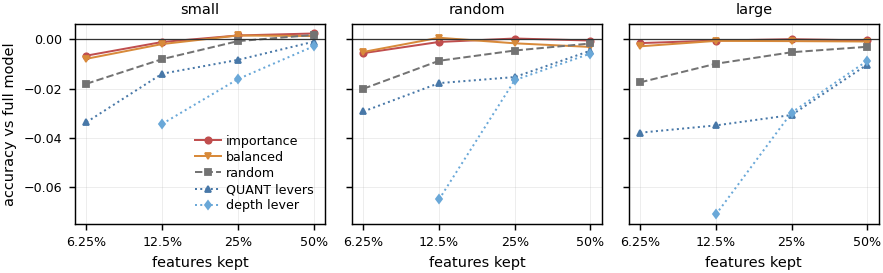

In [8]:
per = (df.groupby(["group", "dataset", "strategy", "budget"])["accuracy"]
       .mean().reset_index())

SHOW = [("importance_sqrt", "importance", "#c04e4e", "o-"),
        ("balanced_sqrt", "balanced", "#d88a3a", "v-"),
        ("random", "random", "0.45", "s--"),
        ("both", "QUANT levers", "#4878a8", "^:"),
        ("depth", "depth lever", "#6aa8d8", "d:")]

# shared y: the depth lever's damage grows with dataset size, which
# per-panel scaling would hide
fig, axes = plt.subplots(1, 3, figsize=(TWO_COL, 2.3), sharey=True)
for ax, group in zip(axes, GROUPS):
    g = per[per["group"] == group]
    if not len(g):
        ax.set_visible(False)
        continue
    full = g[g.strategy == "full"].set_index("dataset")["accuracy"]

    for strat, label, colour, style in SHOW:
        pts = []
        for b, chunk in g[(g.strategy == strat) & (g.budget > 0)].groupby("budget"):
            pair = pd.concat([chunk.set_index("dataset")["accuracy"], full],
                             axis=1).dropna()
            pair.columns = ["a", "b"]
            if len(pair) < len(full):      # partial coverage
                continue
            pts.append((b, (pair.a - pair.b).mean()))
        if pts:
            xs, ys = zip(*pts)
            ax.plot(xs, ys, style, ms=3.5, lw=1.1, color=colour, label=label)

    ax.axhline(0, color="0.2", lw=0.7)
    ax.set_xscale("log", base=2)
    ax.set_xticks([0.0625, 0.125, 0.25, 0.5])
    ax.set_xticklabels(["6.25%", "12.5%", "25%", "50%"])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("features kept")
    ax.set_title(group, fontsize=8)
    if group == GROUPS[0]:
        ax.set_ylabel("accuracy vs full model")
        ax.legend(loc="lower right", frameon=False, handletextpad=0.4,
                  labelspacing=0.25)

save(fig, "fig_budget")
plt.show()

## 5 — Figure 8 reproduced

The paper's sensitivity analysis under its own protocol, with 95% confidence
intervals on the mean. The published figure has none, which is the point:
the intervals are wide enough to contain both the reported pattern and no
pattern at all.

Rows with `fold = -1` are configurations skipped by the feature-count guard
and are excluded.

0 skipped configurations excluded; 50 datasets remain
wrote figures/fig_sensitivity.pdf and .png


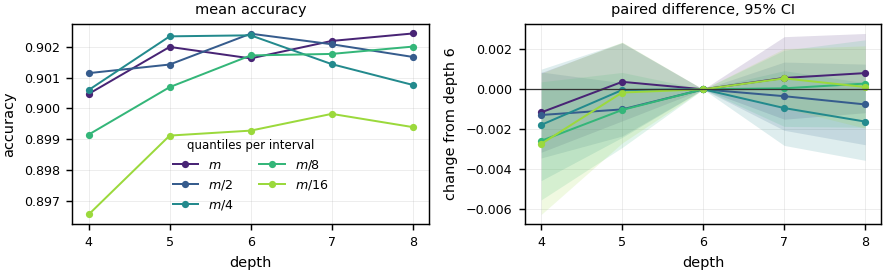


the whole surface spans 0.0059

depth 6 -> 8, paired across datasets
   quantiles   mean diff                95% CI        p
         $m$     +0.0008    [-0.0012, +0.0028]    0.874
       $m/2$     -0.0008    [-0.0028, +0.0013]    0.336
       $m/4$     -0.0016    [-0.0036, +0.0003]    0.040
       $m/8$     +0.0003    [-0.0019, +0.0025]    0.766
      $m/16$     +0.0001    [-0.0019, +0.0022]    0.994


In [9]:
f8 = pd.read_csv(f"{ROOT}/results/fig8_results.csv")
skipped = (f8["fold"] < 0).sum()
f8 = f8[f8["fold"] >= 0]
print(f"{skipped} skipped configurations excluded; "
      f"{f8.dataset.nunique()} datasets remain")

per8 = (f8.groupby(["dataset", "depth", "div"])["accuracy"]
        .mean().reset_index())

LABELS = {1: "$m$", 2: "$m/2$", 4: "$m/4$", 8: "$m/8$", 16: "$m/16$"}
depths = sorted(per8["depth"].unique())
divs = sorted(per8["div"].unique())
colours = plt.cm.viridis(np.linspace(0.1, 0.85, len(divs)))

fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 2.3))

# Left: the surface as the paper draws it.
ax = axes[0]
for colour, div in zip(colours, divs):
    mean = per8[per8["div"] == div].groupby("depth")["accuracy"].mean()
    ax.plot(mean.index, mean.values, "o-", ms=3, lw=1.1, color=colour,
            label=LABELS.get(div, str(div)))
ax.set_xlabel("depth")
ax.set_ylabel("accuracy")
ax.set_xticks(depths)
ax.set_title("mean accuracy", fontsize=8)
ax.legend(title="quantiles per interval", frameon=False, ncol=2,
          title_fontsize=6.5, loc="lower center")

# Right: the change from depth 6, with CIs on the PAIRED difference.
#
# A confidence band on the marginal mean would be dominated by datasets
# differing in difficulty - some sit near 0.5, others near 1.0 - which says
# nothing about whether depth matters. The comparison the analysis actually
# makes is paired: the same datasets at two depths. Dataset difficulty cancels
# in the difference, so this is both the smaller interval and the relevant one.
ax = axes[1]
REF = 6
for colour, div in zip(colours, divs):
    wide = (per8[per8["div"] == div]
            .pivot(index="dataset", columns="depth", values="accuracy"))
    if REF not in wide.columns:
        continue
    means, los, his = [], [], []
    for d in depths:
        if d == REF:                 # the reference is zero by definition
            means.append(0.0)
            los.append(0.0)
            his.append(0.0)
            continue
        paired = wide[[d, REF]].dropna()
        delta = paired[d] - paired[REF]
        sem = delta.std(ddof=1) / np.sqrt(len(delta))
        means.append(delta.mean())
        los.append(delta.mean() - 1.96 * sem)
        his.append(delta.mean() + 1.96 * sem)
    ax.plot(depths, means, "o-", ms=3, lw=1.1, color=colour,
            label=LABELS.get(div, str(div)))
    ax.fill_between(depths, los, his, color=colour, alpha=0.15, lw=0)

ax.axhline(0, color="0.2", lw=0.7)
ax.set_xlabel("depth")
ax.set_ylabel(f"change from depth {REF}")
ax.set_xticks(depths)
ax.set_title("paired difference, 95% CI", fontsize=8)

save(fig, "fig_sensitivity")
plt.show()

span = per8.groupby(["depth", "div"])["accuracy"].mean()
print(f"\nthe whole surface spans {span.max() - span.min():.4f}")

# the step the paper describes: a decline past depth 6 at low quantile counts
from scipy.stats import wilcoxon
print(f"\ndepth {REF} -> 8, paired across datasets")
print(f"{'quantiles':>12}{'mean diff':>12}{'95% CI':>22}{'p':>9}")
for div in divs:
    wide = (per8[per8["div"] == div]
            .pivot(index="dataset", columns="depth", values="accuracy"))
    if REF not in wide.columns or 8 not in wide.columns:
        continue
    paired = wide[[8, REF]].dropna()
    delta = paired[8] - paired[REF]
    sem = delta.std(ddof=1) / np.sqrt(len(delta))
    p = wilcoxon(paired[8], paired[REF]).pvalue
    ci = f"[{delta.mean() - 1.96 * sem:+.4f}, {delta.mean() + 1.96 * sem:+.4f}]"
    print(f"{LABELS.get(div, div):>12}{delta.mean():>+12.4f}{ci:>22}{p:>9.3f}")

## 6 — What each strategy keeps, by depth

Why the depth lever loses to random selection at the same budget: to reach
12.5% it must drop to a single interval level, deleting five of the six scales.
Random thinning keeps every scale, just more sparsely.

This is arithmetic, not a measurement — it holds at every series length.

length 1024: 8994 features, budget 1124
  depth 1:    897 features  fits
  depth 2:   2242 features  
  depth 3:   3811 features  
  depth 4:   5492 features  
  depth 5:   7229 features  
  depth 6:   8994 features  
-> the lever must use depth 1
wrote figures/fig_depth_shares.pdf and .png


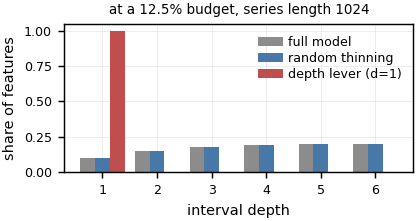

In [10]:
from quant_provenance import feature_provenance

LENGTH, BUDGET = 1024, 0.125

prov = feature_provenance(LENGTH, depth=6, div=4)
n_default = len(prov)
k = int(round(n_default * BUDGET))
base = prov.groupby("depth").size() / n_default

counts = {d: len(feature_provenance(LENGTH, depth=d, div=4))
          for d in range(1, 7)}
fitting = max(d for d, n in counts.items() if n <= k)
lev = feature_provenance(LENGTH, depth=fitting, div=4)
lev_share = lev.groupby("depth").size() / len(lev)

print(f"length {LENGTH}: {n_default} features, budget {k}")
for d, n in counts.items():
    print(f"  depth {d}: {n:>6} features  {'fits' if n <= k else ''}")
print(f"-> the lever must use depth {fitting}")

depths = range(1, 7)
x = np.arange(len(depths))
w = 0.27

fig, ax = plt.subplots(figsize=(ONE_COL, 1.9))
ax.bar(x - w, [base.get(d, 0) for d in depths], w, label="full model",
       color="0.55")
ax.bar(x, [base.get(d, 0) for d in depths], w, label="random thinning",
       color="#4878a8")
ax.bar(x + w, [lev_share.get(d, 0) for d in depths], w,
       label=f"depth lever (d={fitting})", color="#c04e4e")

ax.set_xticks(x)
ax.set_xticklabels([str(d) for d in depths])
ax.set_xlabel("interval depth")
ax.set_ylabel("share of features")
ax.set_title(f"at a {BUDGET:.1%} budget, series length {LENGTH}", fontsize=7.5)
ax.legend(frameon=False, handletextpad=0.4, labelspacing=0.25)

save(fig, "fig_depth_shares")
plt.show()

## 7 — Interval weighting

Difference from the unweighted baseline at each depth, on the datasets that
reach every requested depth. Datasets that saturate earlier are excluded,
since for those the deeper transforms are identical and would flatten any
depth effect.

`pertree_none` is the control: the per-tree machinery with uniform weights,
which separates the effect of weighting from the effect of ensembling.

15 of 20 datasets reach every depth
wrote figures/fig_weighting.pdf and .png


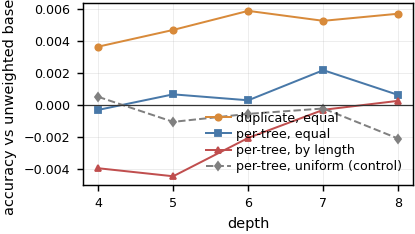

In [11]:
w3 = pd.read_csv(f"{ROOT}/results/weighting_v3_results.csv").drop_duplicates(
    ["dataset", "depth", "div", "fold", "variant"])

sat = w3.groupby("dataset")["saturated_from"].first()
keep = sorted(sat[sat.isna()].index)
print(f"{len(keep)} of {w3.dataset.nunique()} datasets reach every depth")

sub = w3[w3["dataset"].isin(keep)]
perw = (sub.groupby(["dataset", "depth", "div", "variant"])["accuracy"]
        .mean().unstack())

SHOW_W = [("dup_equal", "duplicate, equal", "#d88a3a", "o-"),
          ("pertree_equal", "per-tree, equal", "#4878a8", "s-"),
          ("pertree_length", "per-tree, by length", "#c04e4e", "^-"),
          ("pertree_none", "per-tree, uniform (control)", "0.5", "d--")]

fig, ax = plt.subplots(figsize=(ONE_COL, 2.0))
for variant, label, colour, style in SHOW_W:
    if variant not in perw.columns:
        continue
    pts = []
    for depth in sorted(sub["depth"].unique()):
        a = perw.xs(depth, level="depth")[variant]
        b = perw.xs(depth, level="depth")["baseline"]
        ok = a.notna() & b.notna()
        pts.append((depth, (a[ok] - b[ok]).mean()))
    xs, ys = zip(*pts)
    ax.plot(xs, ys, style, ms=3.5, lw=1.1, color=colour, label=label)

ax.axhline(0, color="0.2", lw=0.7)
ax.set_xlabel("depth")
ax.set_ylabel("accuracy vs unweighted baseline")
ax.set_xticks(sorted(sub["depth"].unique()))
ax.legend(frameon=False, handletextpad=0.4, labelspacing=0.25,
          loc="lower right")

save(fig, "fig_weighting")
plt.show()

## 8 — Accuracy against the class-balanced metrics

Accuracy can hide a cost to minority classes. If selection preserves accuracy
by keeping the features that identify large classes while losing those that
catch rare ones, macro-F1 falls while accuracy does not.

Random selection is shown alongside as the control.

20 datasets, 2 to 52 classes, imbalance up to 18.2:1
majority-class baseline: 0.3895  vs full model 0.9230
wrote figures/fig_metrics.pdf and .png


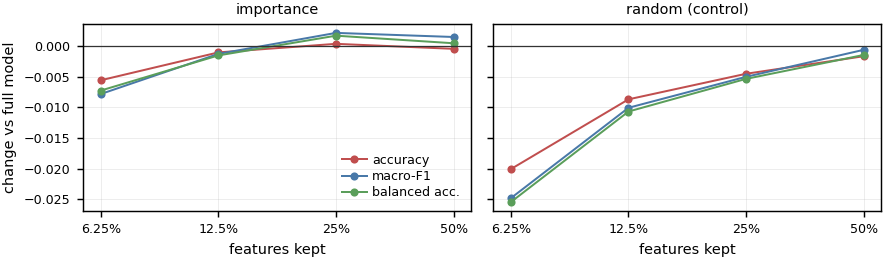

In [12]:
rf1 = pd.read_csv(f"{ROOT}/results/reduction_f1_results.csv").drop_duplicates(
    ["dataset", "fold", "strategy", "budget"])

METRICS = ["accuracy", "macro_f1", "balanced_acc"]
NICE = {"accuracy": "accuracy", "macro_f1": "macro-F1",
        "balanced_acc": "balanced acc."}

perf = (rf1.groupby(["dataset", "strategy", "budget"])[METRICS]
        .mean().reset_index())
fullf = perf[perf.strategy == "full"].set_index("dataset")

info = rf1.groupby("dataset")[["n_classes", "imbalance", "majority_acc"]].first()
print(f"{len(info)} datasets, {info.n_classes.min():.0f} to "
      f"{info.n_classes.max():.0f} classes, imbalance up to "
      f"{info.imbalance.max():.1f}:1")
print(f"majority-class baseline: {info.majority_acc.mean():.4f}  "
      f"vs full model {fullf.accuracy.mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(TWO_COL, 2.2), sharey=True)
# exclude 1.0 (the full model) and -1.0 (QUANT-FAST)
budgets = sorted(b for b in perf["budget"].unique() if 0 < b < 1)

for ax, strat, title in [(axes[0], "importance_sqrt", "importance"),
                         (axes[1], "random", "random (control)")]:
    for colour, m in zip(["#c04e4e", "#4878a8", "#5a9e5a"], METRICS):
        pts = []
        for b in budgets:
            s = perf[(perf.strategy == strat) & (perf.budget == b)]
            pair = pd.concat([s.set_index("dataset")[m], fullf[m]],
                             axis=1).dropna()
            pair.columns = ["a", "b"]
            pts.append((b, (pair.a - pair.b).mean()))
        xs, ys = zip(*pts)
        ax.plot(xs, ys, "o-", ms=3.5, lw=1.1, color=colour, label=NICE[m])

    ax.axhline(0, color="0.2", lw=0.7)
    ax.set_xscale("log", base=2)
    ax.set_xticks(budgets)
    ax.set_xticklabels([f"{100 * b:g}%" for b in budgets])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel("features kept")
    ax.set_title(title, fontsize=8)

axes[0].set_ylabel("change vs full model")
axes[0].legend(frameon=False, handletextpad=0.4, labelspacing=0.25,
               loc="lower right")

save(fig, "fig_metrics")
plt.show()

### Does the cost land on imbalanced datasets?

If aggressive selection hurts rare classes, the macro-F1 loss should grow with
class imbalance. Eight tests, so the Bonferroni threshold is 0.00625.

In [13]:
from scipy.stats import spearmanr

print(f"{'budget':>8}{'rho vs imbalance':>20}{'p':>8}"
      f"{'rho vs n_classes':>20}{'p':>8}")
for b in budgets:
    s = perf[(perf.strategy == "importance_sqrt") & (perf.budget == b)]
    pair = pd.concat([s.set_index("dataset")["macro_f1"],
                      fullf["macro_f1"], info], axis=1).dropna()
    pair.columns = ["a", "b", "n_classes", "imbalance", "majority_acc"]
    delta = pair.a - pair.b
    r1, p1 = spearmanr(pair["imbalance"], delta)
    r2, p2 = spearmanr(pair["n_classes"], delta)
    star = "  *" if p1 < 0.05 / (2 * len(budgets)) else ""
    print(f"{b:>8.1%}{r1:>20.3f}{p1:>8.3f}{r2:>20.3f}{p2:>8.3f}{star}")

print("\n  * survives Bonferroni correction across the eight tests")

  budget    rho vs imbalance       p    rho vs n_classes       p
    6.2%              -0.685   0.001              -0.243   0.302  *
   12.5%              -0.091   0.702              -0.101   0.670
   25.0%              -0.171   0.471              -0.164   0.491
   50.0%              -0.015   0.949               0.169   0.476

  * survives Bonferroni correction across the eight tests
